# Project Overview
This project focuses on analysing retail sales data using Python and its data analysis libraries.
# Business Objective
The objective is to identify sales trends,evaluate profitability,understand customer purchasing behaviour,and generate actionable business recommendations.
# Tools and Techinques
*   Python
*   Pandas
*   Numpy
*   Matplotlib
*   Seaborn
# Key Business Questions
1.   What are the overall sales and profit trends?
2.  which products and categories perform best?
3.   Which regions generate the highest revenue?
4.   Which products contribute to business losses?
5.  How can the company improve its profitability?












In [1]:
! pip install dataset

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [dataset]


In [2]:
# Data manipulation
import pandas as pd
import numpy as np
# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
pd.set_option('display.max_columns', None)


In [4]:
from google.colab import files
uploaded = files.upload()

Saving Sample_ Superstore.csv to Sample_ Superstore.csv


In [5]:
df = pd.read_csv('Sample_ Superstore.csv')
print('Dataset load sucessfully')

Dataset load sucessfully


In [6]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Corporate,United States,Los Angeles,California,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [7]:

df.shape

(9994, 19)

In [8]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Segment',
 'Country',
 'City',
 'State',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Row ID        9994 non-null   int64  
 1   Order ID      9994 non-null   object 
 2   Order Date    9994 non-null   object 
 3   Ship Date     9994 non-null   object 
 4   Ship Mode     9994 non-null   object 
 5   Customer ID   9994 non-null   object 
 6   Segment       9994 non-null   object 
 7   Country       9994 non-null   object 
 8   City          9994 non-null   object 
 9   State         9994 non-null   object 
 10  Region        9994 non-null   object 
 11  Product ID    9994 non-null   object 
 12  Category      9994 non-null   object 
 13  Sub-Category  9994 non-null   object 
 14  Product Name  9994 non-null   object 
 15  Sales         9994 non-null   float64
 16  Quantity      9994 non-null   int64  
 17  Discount      9994 non-null   float64
 18  Profit        9994 non-null 

In [10]:
df.describe()

,Row ID,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,229.858001,3.789574,0.156203,28.656896
std,2885.163629,623.245101,2.225110,0.206452,234.260108
min,1.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,22638.480000,14.000000,0.800000,8399.976000


In [11]:
#missing Values
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Segment,0
Country,0
City,0
State,0


In [12]:
# Duplicate
df.duplicated().sum()

np.int64(0)

In [13]:
df.nunique()

,0
Row ID,9994
Order ID,5009
Order Date,1237
Ship Date,1334
Ship Mode,4
Customer ID,793
Segment,3
Country,1
City,531
State,49


In [14]:
df['Category'].value_counts()

,count
Category,
Office Supplies,6026
Furniture,2121
Technology,1847


In [15]:
df[['Order Date','Ship Date']].head(10)

,Order Date,Ship Date
0,11-08-2016,11-11-2016
1,11-08-2016,11-11-2016
2,06-12-2016,6/16/2016
3,10-11-2015,10/18/2015
4,10-11-2015,10/18/2015
5,06-09-2014,6/14/2014
6,06-09-2014,6/14/2014
7,06-09-2014,6/14/2014
8,06-09-2014,6/14/2014
9,06-09-2014,6/14/2014


In [16]:
df['Order ID'].nunique()

5009

In [17]:
df['Customer ID'].nunique()

793

In [18]:
df['Order Date'] = pd.to_datetime(df['Order Date'],format='mixed')

In [19]:
df['Ship Date'] = pd.to_datetime(df['Ship Date'],format='mixed')

In [20]:
df[['Order Date','Ship Date']].head(20)

,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18
5,2014-06-09,2014-06-14
6,2014-06-09,2014-06-14
7,2014-06-09,2014-06-14
8,2014-06-09,2014-06-14
9,2014-06-09,2014-06-14


In [21]:
# Create backup
df_raw = df.copy()
# Create a working Dataset
df = df_raw.copy()
print('Backup Sucessfully')

Backup Sucessfully


In [22]:
df[['Order Date','Ship Date']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order Date  9994 non-null   datetime64[ns]
 1   Ship Date   9994 non-null   datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 156.3 KB


In [23]:
df['Order Date'].min(),df['Order Date'].max()

(Timestamp('2014-01-03 00:00:00'), Timestamp('2017-12-30 00:00:00'))

In [24]:
df[['Order Date','Ship Date']].isnull().sum()

,0
Order Date,0
Ship Date,0


In [25]:
df[['Sales','Quantity','Discount','Profit']].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [26]:
df['Shipping_Days'] = (df['Ship Date'] - df['Order Date']).dt.days

In [27]:
df['Order_Month'] = df['Order Date'].dt.month_name()

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Segment        9994 non-null   object        
 7   Country        9994 non-null   object        
 8   City           9994 non-null   object        
 9   State          9994 non-null   object        
 10  Region         9994 non-null   object        
 11  Product ID     9994 non-null   object        
 12  Category       9994 non-null   object        
 13  Sub-Category   9994 non-null   object        
 14  Product Name   9994 non-null   object        
 15  Sales          9994 n

In [29]:
df['Order_Year'] = df['Order Date'].dt.year

In [30]:
df['Order_Weekday'] = df['Order Date'].dt.day_name()

In [31]:
#Verify new columns
df[[ 'Order Date'   ,'Order_Month','Order_Weekday','Shipping_Days','Order_Year']].head()

,Order Date,Order_Month,Order_Weekday,Shipping_Days,Order_Year
0,2016-11-08,November,Tuesday,3,2016
1,2016-11-08,November,Tuesday,3,2016
2,2016-06-12,June,Sunday,4,2016
3,2015-10-11,October,Sunday,7,2015
4,2015-10-11,October,Sunday,7,2015


In [32]:
df['Shipping_Days'].describe()

,Shipping_Days
count,9994.000000
mean,3.958175
std,1.747567
min,0.000000
25%,3.000000
50%,4.000000
75%,5.000000
max,7.000000


In [33]:
print('Dataset Shape',df.shape)
print('missing values',df.isnull().sum())
print('Duplicate values',df.duplicated().sum())

Dataset Shape (9994, 23)
missing values Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Segment          0
Country          0
City             0
State            0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Shipping_Days    0
Order_Month      0
Order_Year       0
Order_Weekday    0
dtype: int64
Duplicate values 0


In [34]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()

In [35]:
print("Total Sales",round (total_sales,2))
print("Total Profit",round (total_profit,2))
print("Total Orders",total_orders)
print("Total Customers",total_customers)

Total Sales 2297200.86
Total Profit 286397.02
Total Orders 5009
Total Customers 793


In [36]:
profit_margin = (total_profit / total_sales) * 100
print("Profit Margin",round(profit_margin,2),"%")


Profit Margin 12.47 %


In [37]:
#Category wise sales and profit
category_analysis = df.groupby('Category').agg(Total_Sales=('Sales','sum'),Total_Profit=('Profit','sum'),
Total_Quantity=('Quantity','sum')).round(2)
category_analysis

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906
Technology,836154.03,145454.95,6939


In [38]:
category_analysis.sort_values(by='Total_Sales',ascending=False)

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,836154.03,145454.95,6939
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906


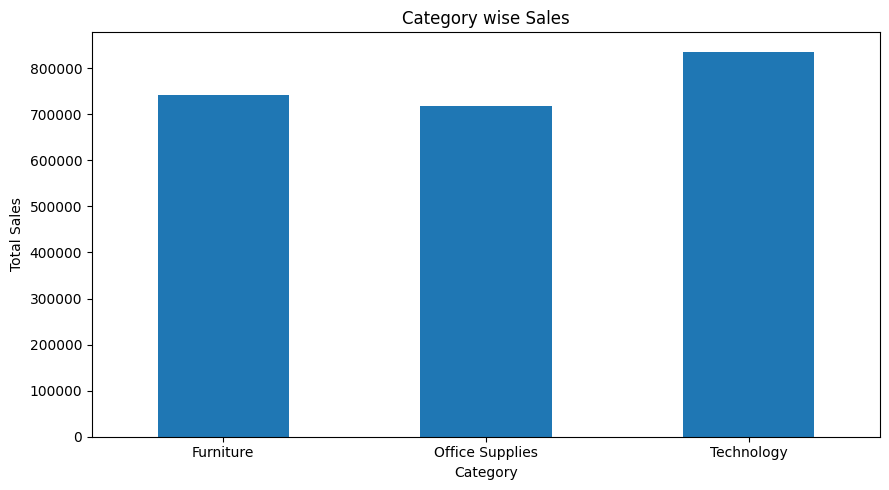

In [39]:
category_analysis['Total_Sales'].plot(kind='bar',figsize=(9,5),title='Category wise Sales')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [40]:
# regional analysis
region_analysis = df.groupby('Region').agg(Total_Sales=('Sales','sum'),Total_Profit=('Profit','sum'),
Total_Quantity=('Quantity','sum'),Total_Orders=('Order ID','nunique')).round(2)
region_analysis.sort_values(by='Total_Sales',ascending=False)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Region,,,,
West,725457.82,108418.45,12266,1611
East,678781.24,91522.78,10618,1401
Central,501239.89,39706.36,8780,1175
South,391721.90,46749.43,6209,822


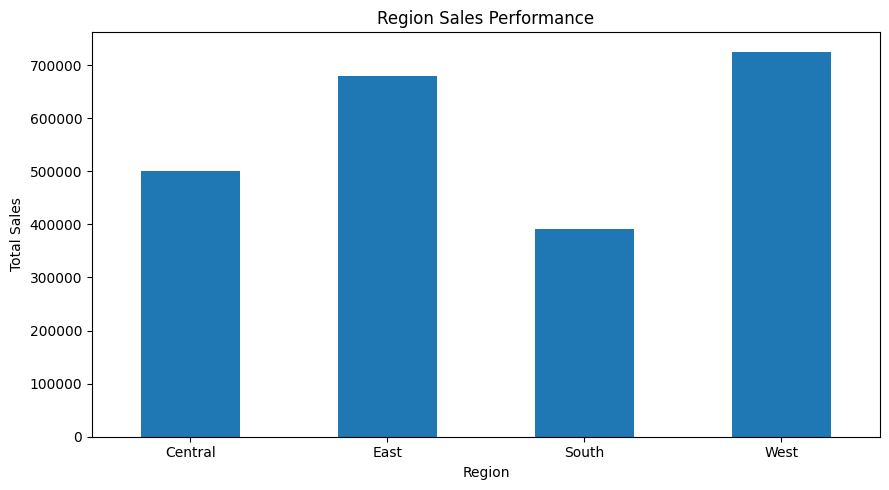

In [41]:
region_analysis['Total_Sales'].plot(kind='bar',figsize=(9,5),title='Region Sales Performance')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [42]:
region_analysis['Profit_Margin'] = (region_analysis['Total_Profit'] / region_analysis['Total_Sales']) * 100
region_analysis.sort_values(by='Profit_Margin',ascending=False)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Region,,,,,
West,725457.82,108418.45,12266,1611,14.944832
East,678781.24,91522.78,10618,1401,13.483399
South,391721.90,46749.43,6209,822,11.934342
Central,501239.89,39706.36,8780,1175,7.921628


In [43]:
# Monthly Sales Trend Analysis
monthly_sales = df.groupby('Order_Month').agg(Total_Sales=('Sales','sum'))

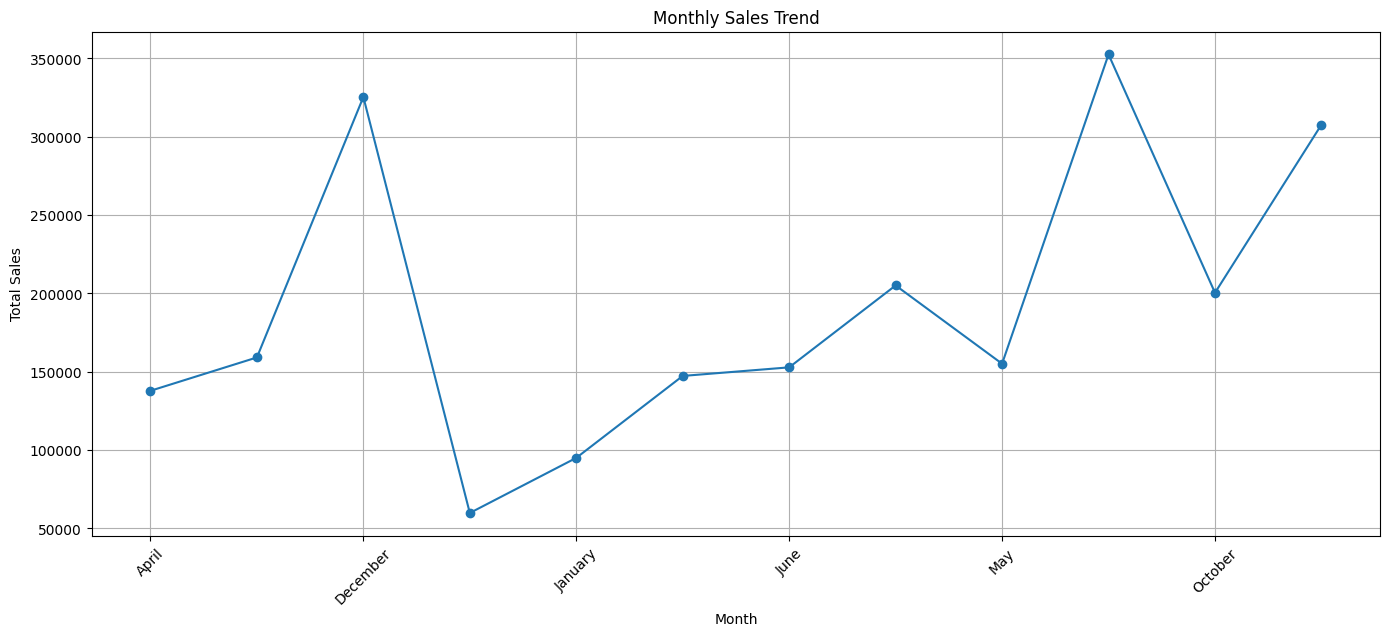

In [44]:
plt.figure(figsize=(14,6))
monthly_sales['Total_Sales'].plot(kind='line',marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.grid(True)
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

In [45]:
# yearly sales performance
yearly_sales = df.groupby('Order_Year').agg(Total_Sales=('Sales','sum'))
yearly_sales.sort_values(by='Order_Year',ascending=False)


,Total_Sales
Order_Year,
2017,733215.2552
2016,609205.5980
2015,470532.5090
2014,484247.4981


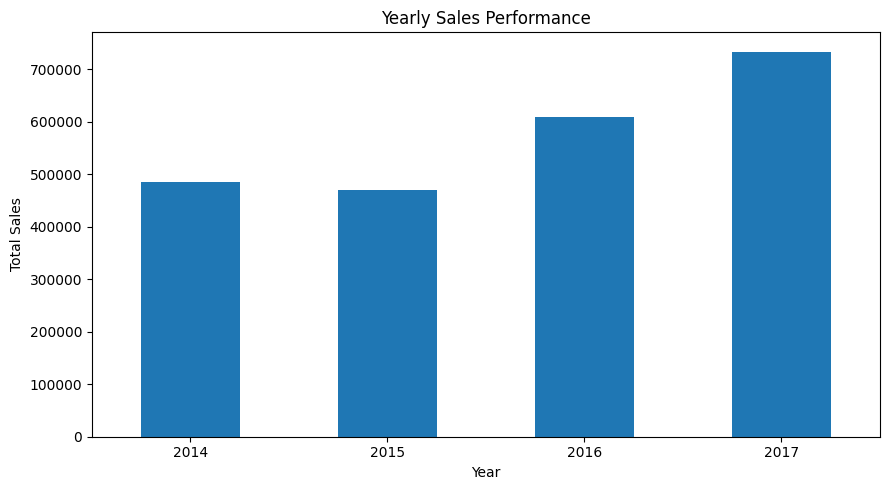

In [46]:
yearly_sales['Total_Sales'].plot(kind='bar',figsize=(9,5),title='Yearly Sales Performance')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [47]:
#Customer Analysis Top 10 customer sales
customer_Sales = df.groupby('Customer ID')['Sales'].sum().reset_index()
customer_Sales.sort_values(by='Sales',ascending=False).head(10)


,Customer ID,Sales
700,SM-20320,25043.050
741,TC-20980,19052.218
621,RB-19360,15117.339
730,TA-21385,14595.620
6,AB-10105,14473.571
434,KL-16645,14175.229
669,SC-20095,14142.334
327,HL-15040,12873.298
683,SE-20110,12209.438
131,CC-12370,12129.072


In [48]:
# Segment Analysis
segment_analysis = df.groupby('Segment').agg({'Sales':'sum','Profit':'sum','Customer ID':'nunique'}).reset_index()
Segment =segment_analysis.sort_values(by='Sales',ascending=False)

In [49]:
# Customer Profitabilty analysis Top 10 profitable customers.
customer_profit = df.groupby('Customer ID').agg({'Profit':'sum','Sales':'sum'}).reset_index()
customer_profit.sort_values(by='Profit',ascending=False).head(10)


,Customer ID,Profit,Sales
741,TC-20980,8981.3239,19052.218
621,RB-19360,6976.0959,15117.339
669,SC-20095,5757.4119,14142.334
327,HL-15040,5622.4292,12873.298
6,AB-10105,5444.8055,14473.571
730,TA-21385,4703.7883,14595.620
160,CM-12385,3899.8904,8954.020
424,KD-16495,3038.6254,8181.256
48,AR-10540,2884.6208,6608.448
234,DR-12940,2869.0760,8350.868


In [50]:
# Lossing - Making Customers
loss_customers = customer_profit[customer_profit['Profit'] < 0]
loss_customers.sort_values(by='Profit',ascending=True).head(10)

,Customer ID,Profit,Sales
180,CS-12505,-6626.3895,5690.055
310,GT-14635,-4108.6589,9351.212
459,LF-17185,-3583.9770,3930.509
711,SR-20425,-3333.9144,3233.481
322,HG-14965,-2797.9635,3247.642
555,NC-18415,-2204.8072,2218.990
666,SB-20290,-2082.7451,8057.891
700,SM-20320,-1980.7393,25043.050
165,CP-12340,-1850.3029,5888.275
560,NF-18385,-1695.9714,8322.826


In [51]:
total_loss_making_customers = loss_customers.value_counts().sum()

In [52]:
total_loss = loss_customers['Profit'].sum()

# Customer Profitabilty Classification
*   High Value: Profit > 1,000
*   Medium Value: Profit between 0 and 999.99
*   Loss Making: Profit below 0






In [53]:
def classify_customer(profit):
    if profit >= 1000:
        return 'High Value'
    elif profit >=0 :
        return 'Medium Value'
    else:
        return 'Loss Making'
customer_profit['Customer Category'] = customer_profit['Profit'].apply(classify_customer)
customer_profit['Customer Category'].value_counts()

,count
Customer Category,
Medium Value,538
Loss Making,155
High Value,100


# Here we are going to show top 10 profitable customers .

In [54]:
top_customer =customer_profit.sort_values(by='Profit',ascending=False).head(10)
top_customer


,Customer ID,Profit,Sales,Customer Category
741,TC-20980,8981.3239,19052.218,High Value
621,RB-19360,6976.0959,15117.339,High Value
669,SC-20095,5757.4119,14142.334,High Value
327,HL-15040,5622.4292,12873.298,High Value
6,AB-10105,5444.8055,14473.571,High Value
730,TA-21385,4703.7883,14595.620,High Value
160,CM-12385,3899.8904,8954.020,High Value
424,KD-16495,3038.6254,8181.256,High Value
48,AR-10540,2884.6208,6608.448,High Value
234,DR-12940,2869.0760,8350.868,High Value


/tmp/ipykernel_670/2379758154.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='Customer ID',x='Profit',data=top_customer , palette='viridis')


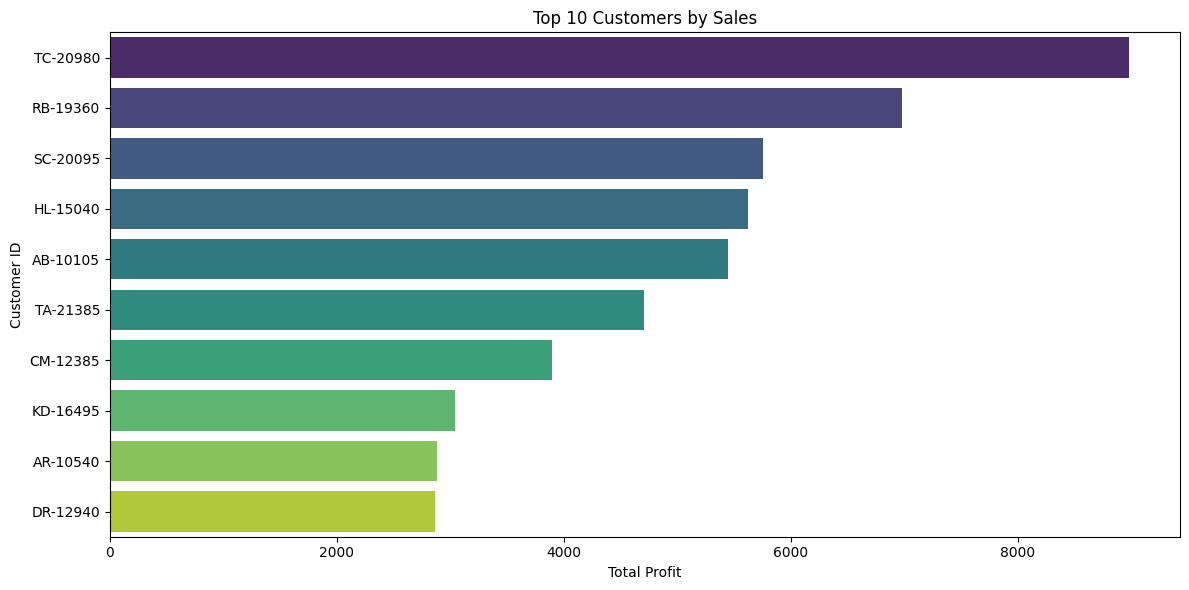

In [55]:
plt.figure(figsize=(12,6))
sns.barplot(y='Customer ID',x='Profit',data=top_customer , palette='viridis')
plt.title('Top 10 Customers by Sales')
plt.xlabel('Total Profit')
plt.ylabel('Customer ID')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# top 10 loss-making customers

In [56]:
loss_top10 = loss_customers.sort_values(by='Profit',ascending=True).head(10)
loss_top10

,Customer ID,Profit,Sales
180,CS-12505,-6626.3895,5690.055
310,GT-14635,-4108.6589,9351.212
459,LF-17185,-3583.9770,3930.509
711,SR-20425,-3333.9144,3233.481
322,HG-14965,-2797.9635,3247.642
555,NC-18415,-2204.8072,2218.990
666,SB-20290,-2082.7451,8057.891
700,SM-20320,-1980.7393,25043.050
165,CP-12340,-1850.3029,5888.275
560,NF-18385,-1695.9714,8322.826


/tmp/ipykernel_670/3837034180.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='Customer ID',x='Profit',data=loss_top10 , palette='rocket')


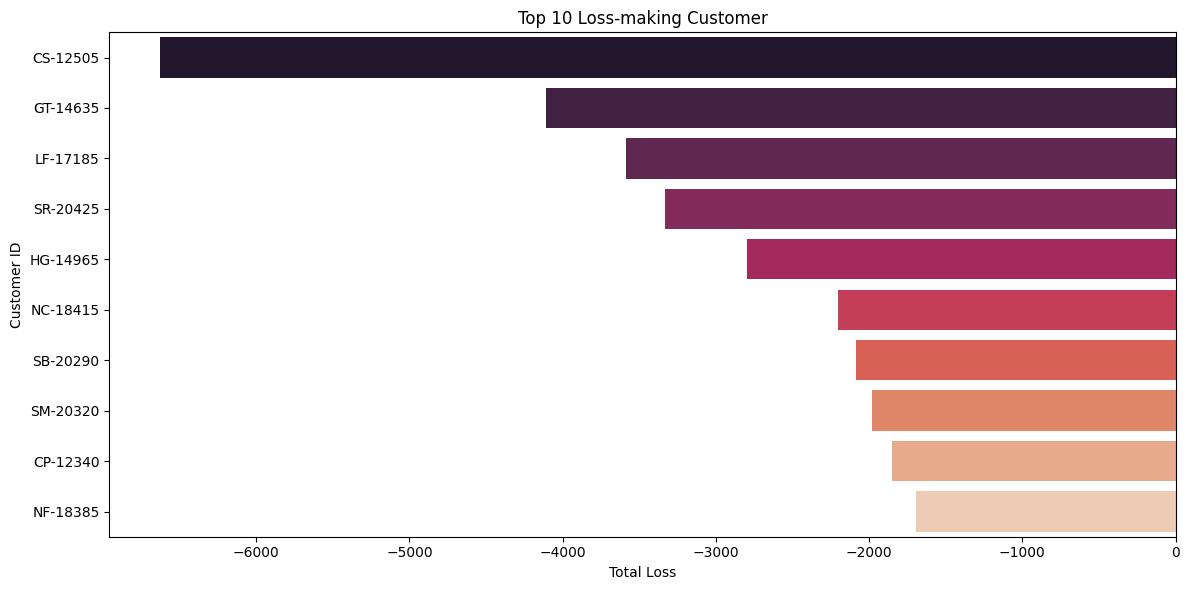

In [57]:
plt.figure(figsize=(12,6))
sns.barplot(y='Customer ID',x='Profit',data=loss_top10 , palette='rocket')
plt.title('Top 10 Loss-making Customer')
plt.xlabel('Total Loss')
plt.ylabel('Customer ID')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Customer Segment-wise Sales & Profit Analysis

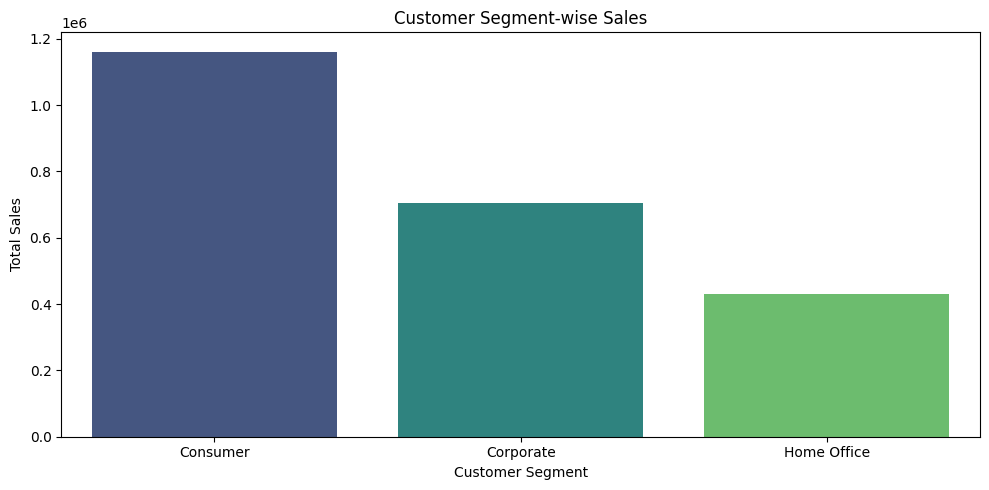

In [58]:
# Sales comparison Chart
plt.figure(figsize=(10,5))
sns.barplot(x='Segment',y='Sales',hue='Segment',palette='viridis',data=Segment)
plt.title('Customer Segment-wise Sales')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

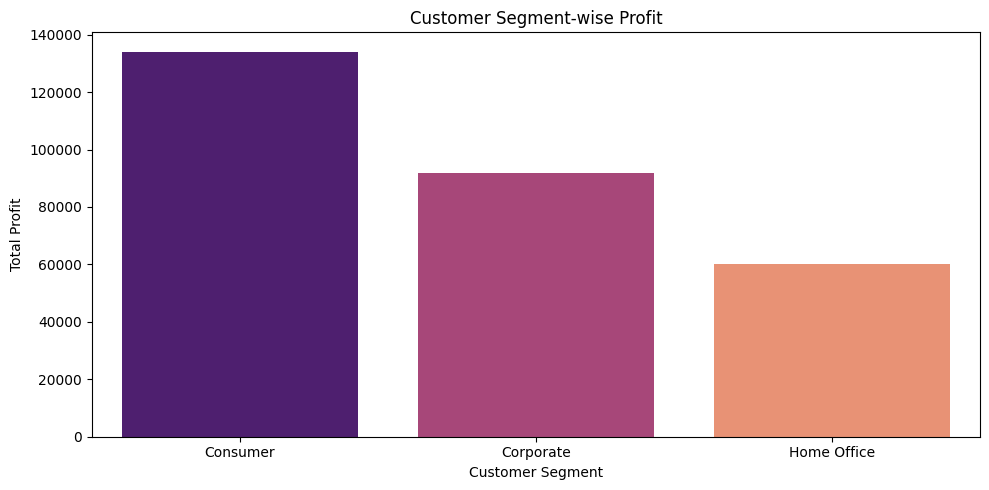

In [59]:
# Profit comparison Chart
plt.figure(figsize=(10,5))
sns.barplot(x='Segment',y='Profit',hue='Segment',palette='magma',data=Segment)
plt.title('Customer Segment-wise Profit')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [60]:
Segment


,Segment,Sales,Profit,Customer ID
0,Consumer,1.161401e+06,134119.2092,409
1,Corporate,7.061464e+05,91979.1340,236
2,Home Office,4.296531e+05,60298.6785,148


In [61]:
# Top 10 Products by Sales
product_analysis = df.groupby('Product Name').agg({'Sales':'sum','Quantity':'sum','Profit':'sum'}).reset_index()
top_products =product_analysis.sort_values(by='Sales',ascending=False).head(10)
top_products

,Product Name,Sales,Quantity,Profit
404,Canon imageCLASS 2200 Advanced Copier,61599.824,20,2.519993e+04
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,31,7.753039e+03
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,-1.811078e+03
786,HON 5400 Series Task Chairs for Big and Tall,21870.576,39,5.684342e-14
686,GBC DocuBind TL300 Electric Binding System,19823.479,37,2.233505e+03
688,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,48,7.609800e+02
805,Hewlett Packard LaserJet 3310 Copier,18839.686,38,6.983884e+03
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,12,4.094977e+03
683,GBC DocuBind P400 Electric Binding System,17965.068,27,-1.878166e+03
813,High Speed Automatic Electric Letter Opener,17030.312,11,-2.620048e+02


In [62]:
total_sales = top_products['Sales'].sum()
total_profit = top_products['Profit'].sum()
print('Total Sales',total_sales)
print('Total Profit',total_profit)

Total Sales 244620.204
Total Profit 43075.0629


In [63]:
top_profit_products = product_analysis.sort_values(by='Profit',ascending=False).head(10)
top_profit_products

,Product Name,Sales,Quantity,Profit
404,Canon imageCLASS 2200 Advanced Copier,61599.824,20,25199.9280
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,31,7753.0390
805,Hewlett Packard LaserJet 3310 Copier,18839.686,38,6983.8836
400,Canon PC1060 Personal Laser Copier,11619.834,19,4570.9347
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,12,4094.9766
165,Ativa V4110MDD Micro-Cut Shredder,7699.890,11,3772.9461
19,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,11,3717.9714
1276,Plantronics Savi W720 Multi-Device Wireless He...,9367.290,24,3696.2820
895,Ibico EPK-21 Electric Binding System,15875.916,13,3345.2823
1840,Zebra ZM400 Thermal Label Printer,6965.700,6,3343.5360


/tmp/ipykernel_670/2176694421.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='Product Name',x='Profit',data=top_profit_products , palette='Blues_r')


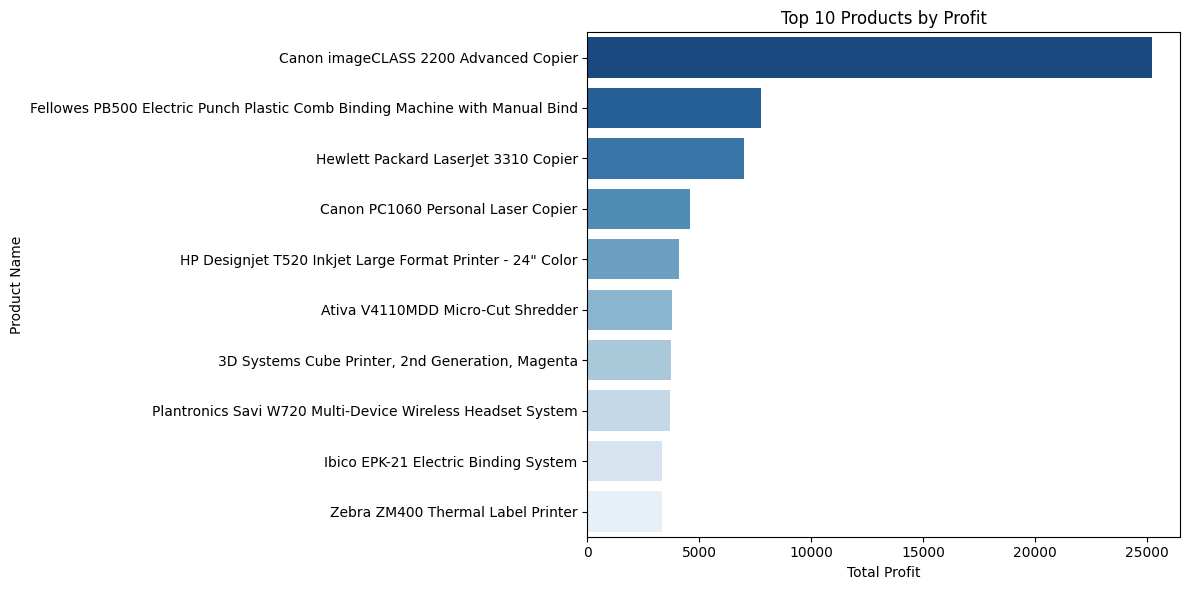

In [64]:
plt.figure(figsize=(12,6))
sns.barplot(y='Product Name',x='Profit',data=top_profit_products , palette='Blues_r')
plt.title('Top 10 Products by Profit')
plt.xlabel('Total Profit')
plt.ylabel('Product Name')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [65]:
loss_products = product_analysis[product_analysis['Profit'] < 0].sort_values(by='Profit',ascending=True).head(10)

In [66]:
# Total loss making products
len(loss_products)

10

/tmp/ipykernel_670/32298510.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='Product Name',x='Profit',data=loss_products , palette='rocket')


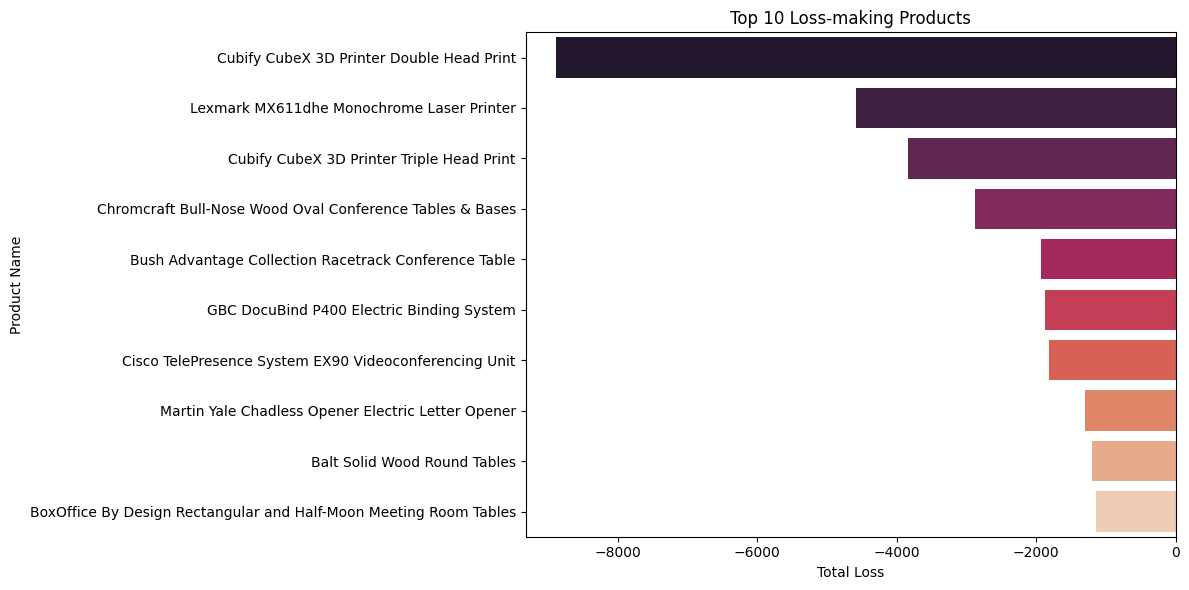

In [67]:
plt.figure(figsize=(12,6))
sns.barplot(y='Product Name',x='Profit',data=loss_products , palette='rocket')
plt.title('Top 10 Loss-making Products')
plt.xlabel('Total Loss')
plt.ylabel('Product Name')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [68]:
loss_products['Profit'].sum()

np.float64(-29458.3708)

In [69]:
df['Month']=df['Order Date'].dt.month

In [70]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping_Days,Order_Month,Order_Year,Order_Weekday,Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3,November,2016,Tuesday,11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,United States,Henderson,Kentucky,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3,November,2016,Tuesday,11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Corporate,United States,Los Angeles,California,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4,June,2016,Sunday,6
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7,October,2015,Sunday,10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,United States,Fort Lauderdale,Florida,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7,October,2015,Sunday,10


In [71]:
# Monthly Sales Calculation
monthly_sales = df.groupby(['Order_Year','Month','Order_Month'])['Sales'].sum().reset_index()
monthly_sales= monthly_sales.sort_values(by=['Order_Year','Month'])
monthly_sales.head(15)

,Order_Year,Month,Order_Month,Sales
0,2014,1,January,14236.8950
1,2014,2,February,4519.8920
2,2014,3,March,55691.0090
3,2014,4,April,28295.3450
4,2014,5,May,23648.2870
5,2014,6,June,34595.1276
6,2014,7,July,33946.3930
7,2014,8,August,27909.4685
8,2014,9,September,81777.3508
9,2014,10,October,31453.3930


In [72]:
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
monthly_sales['Order_Month']=pd.Categorical(monthly_sales['Order_Month'],categories=month_order,ordered=True)

In [73]:
monthly_sales['Order_Year']=monthly_sales['Order_Year'].astype(int)
monthly_sales['Month']=monthly_sales['Month'].astype(int)
monthly_sales= monthly_sales.sort_values(by=['Order_Year','Month'])


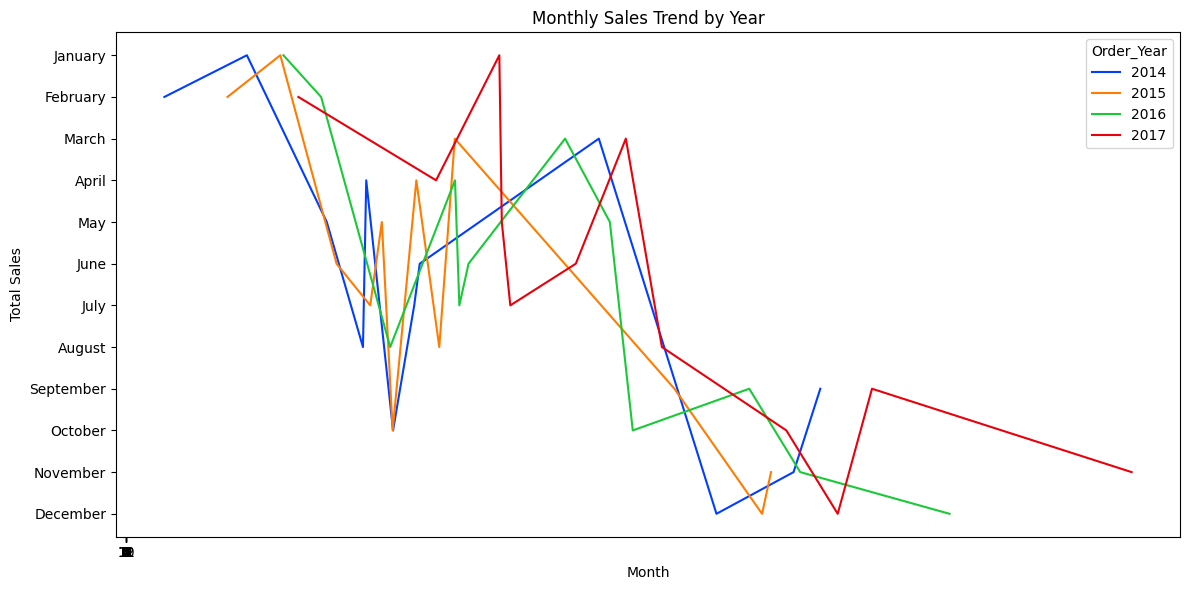

In [74]:
plt.figure(figsize=(12,6))
sns.lineplot(y='Order_Month',x='Sales',hue='Order_Year',data=monthly_sales,markers=0,markersize=2,errorbar=None,palette='bright')
plt.title('Monthly Sales Trend by Year')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1,13))
plt.tight_layout()
plt.show()

In [81]:
# Year-wise Sales Analysis
yearly_sales = df.groupby('Order_Year')['Sales'].sum().sort_index()
print('Highest Sales year',yearly_sales.idxmax())
print('Total Sales',yearly_sales.max())

Highest Sales year 2017
Total Sales 733215.2552


In [78]:
yearly_sales

,Order_Year,Sales
0,2014,484247.4981
1,2015,470532.5090
2,2016,609205.5980
3,2017,733215.2552


# Year-Over-Year Growth

In [83]:
yearly_growth= yearly_sales.pct_change() * 100
yearly_growth


,Sales
Order_Year,
2014,NaN
2015,-2.832227
2016,29.471521
2017,20.355962


/tmp/ipykernel_670/2743674763.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=yearly_growth.index,y=yearly_growth.values,palette='viridis')


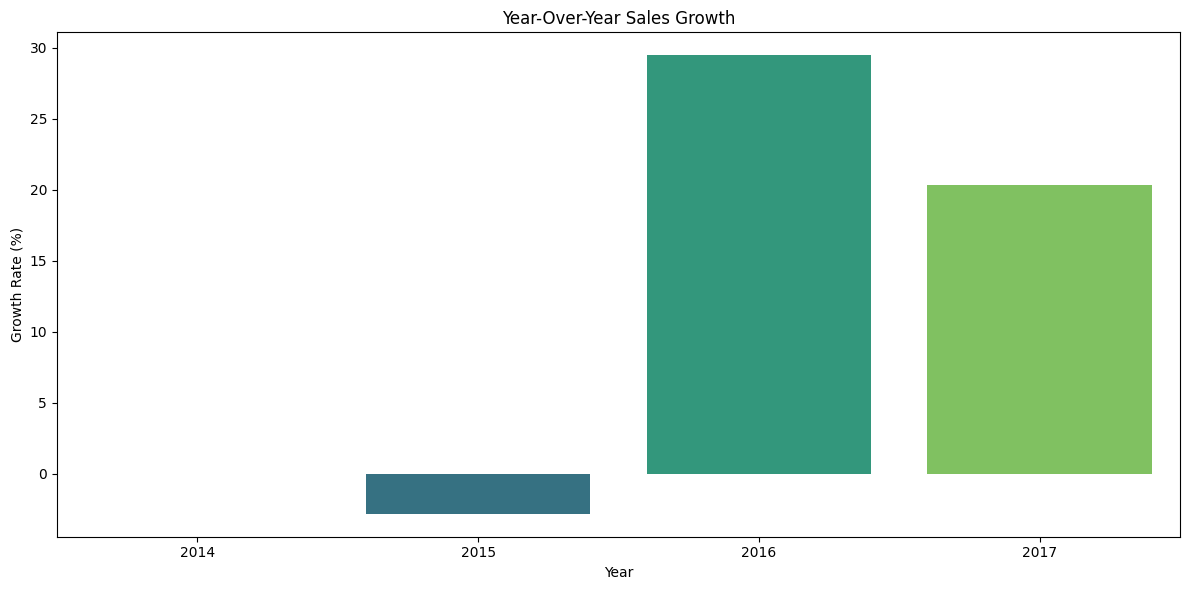

In [84]:
plt.figure(figsize=(12,6))
sns.barplot(x=yearly_growth.index,y=yearly_growth.values,palette='viridis')
plt.title('Year-Over-Year Sales Growth')
plt.xlabel('Year')
plt.ylabel('Growth Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [85]:
yearly_profit= df.groupby('Order_Year')['Profit'].sum().sort_index()
yearly_profit

,Profit
Order_Year,
2014,49543.9741
2015,61618.6037
2016,81795.1743
2017,93439.2696


In [87]:
# Calculate yearly sales and profit together
yearly_performance = df.groupby('Order_Year').agg(Total_Sales=('Sales','sum'),Total_Profit=('Profit','sum'))
yearly_performance

,Total_Sales,Total_Profit
Order_Year,,
2014,484247.4981,49543.9741
2015,470532.5090,61618.6037
2016,609205.5980,81795.1743
2017,733215.2552,93439.2696


In [89]:
highest_profit_year = print("Highest profit year",yearly_performance.idxmax())

Highest profit year Total_Sales     2017
Total_Profit    2017
dtype: int32


# Yearly Sales vs Profit Visualization

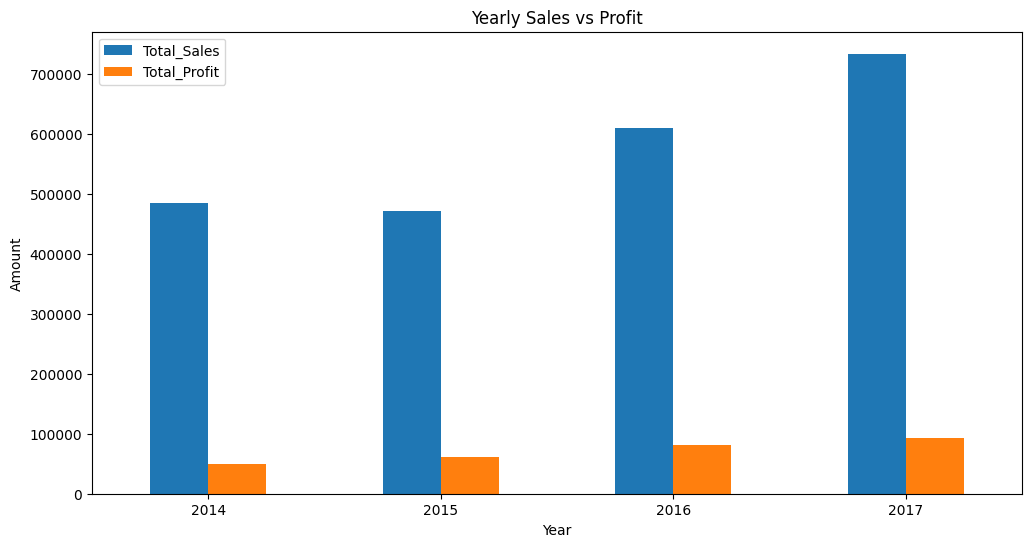

In [91]:
yearly_performance.plot(kind='bar',figsize=(12,6))
plt.title('Yearly Sales vs Profit')
plt.xlabel('Year')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.show()

In [93]:
# Yearly Profit margin
yearly_profit_margin = (yearly_performance['Total_Profit'] / yearly_performance['Total_Sales']) * 100
yearly_profit_margin

,0
Order_Year,
2014,10.231126
2015,13.095504
2016,13.426530
2017,12.743771


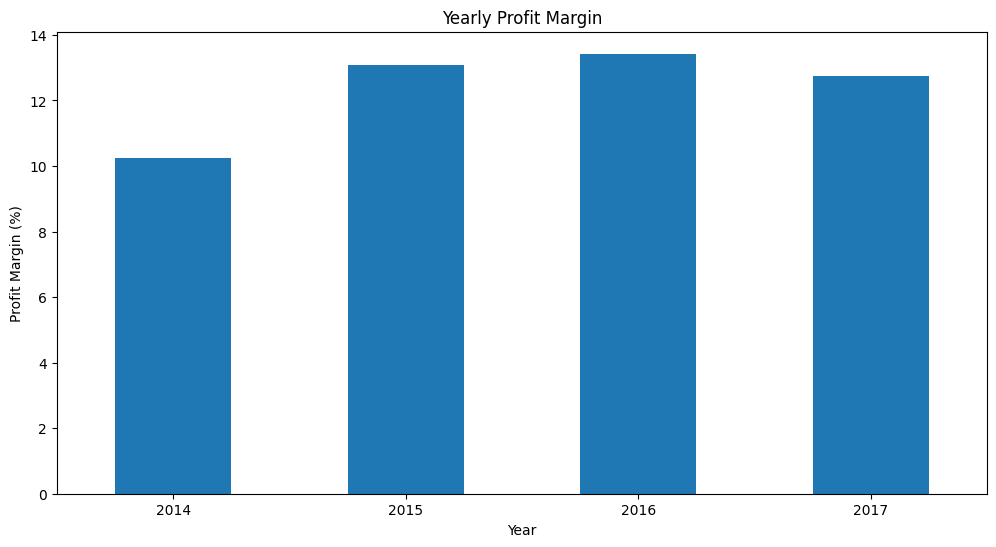

In [96]:
yearly_profit_margin.plot(kind='bar',figsize=(12,6))
plt.title('Yearly Profit Margin')
plt.xlabel('Year')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=0)
plt.show()

# Discount Analysis


In [98]:
discount_analysis = df.groupby('Discount').agg({'Sales':'sum','Profit':'mean'})
discount_analysis

,Sales,Profit
Discount,,
0.00,1.087908e+06,66.900292
0.10,5.436935e+04,96.055074
0.15,2.755852e+04,27.288298
0.20,7.645944e+05,24.702572
0.30,1.032267e+05,-45.679636
0.32,1.449346e+04,-88.560656
0.40,1.164178e+05,-111.927429
0.45,5.484974e+03,-226.646464
0.50,5.891854e+04,-310.703456


In [100]:
discount_profit= df.groupby('Discount').agg({'Profit':'mean','Sales':'sum'})
discount_profit

,Profit,Sales
Discount,,
0.00,66.900292,1.087908e+06
0.10,96.055074,5.436935e+04
0.15,27.288298,2.755852e+04
0.20,24.702572,7.645944e+05
0.30,-45.679636,1.032267e+05
0.32,-88.560656,1.449346e+04
0.40,-111.927429,1.164178e+05
0.45,-226.646464,5.484974e+03
0.50,-310.703456,5.891854e+04


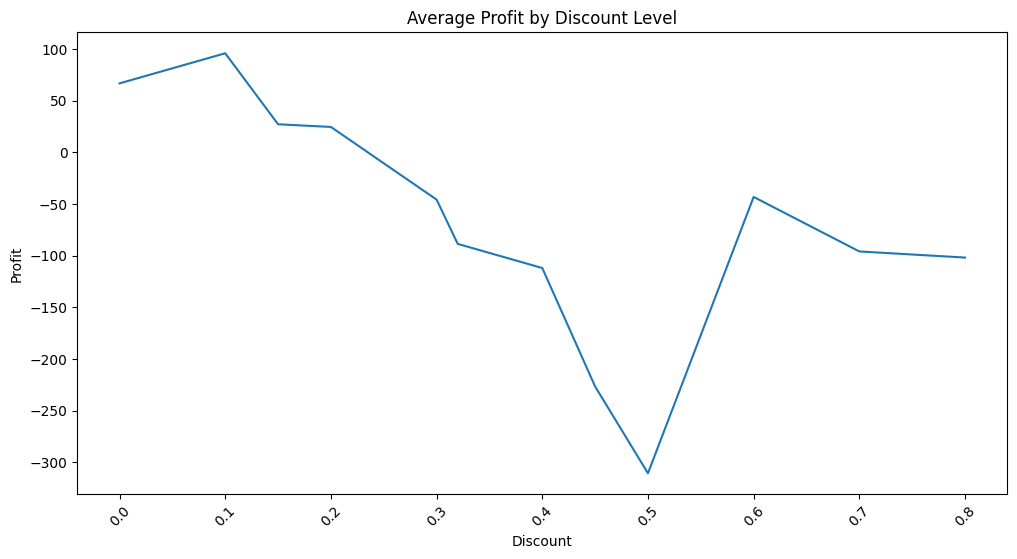

In [102]:
discount_profit['Profit'].plot(kind='line',figsize=(12,6))
plt.title('Average Profit by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.xticks(rotation=45)
plt.show()

# Shipping Mode Analysis

In [103]:
# Group by Ship Mode
shipping_analysis = df.groupby('Ship Mode').agg({'Sales':'sum','Profit':'sum','Order ID':'count'})
shipping_analysis


,Sales,Profit,Order ID
Ship Mode,,,
First Class,3.514284e+05,48969.8399,1538
Same Day,1.283631e+05,15891.7589,543
Second Class,4.591936e+05,57446.6354,1945
Standard Class,1.358216e+06,164088.7875,5968


In [104]:
# Calculate Profit Margin
shipping_analysis['Profit Margin'] = (shipping_analysis['Profit'] / shipping_analysis['Sales']) * 100
shipping_analysis

,Sales,Profit,Order ID,Profit Margin
Ship Mode,,,,
First Class,3.514284e+05,48969.8399,1538,13.934513
Same Day,1.283631e+05,15891.7589,543,12.380315
Second Class,4.591936e+05,57446.6354,1945,12.510331
Standard Class,1.358216e+06,164088.7875,5968,12.081202


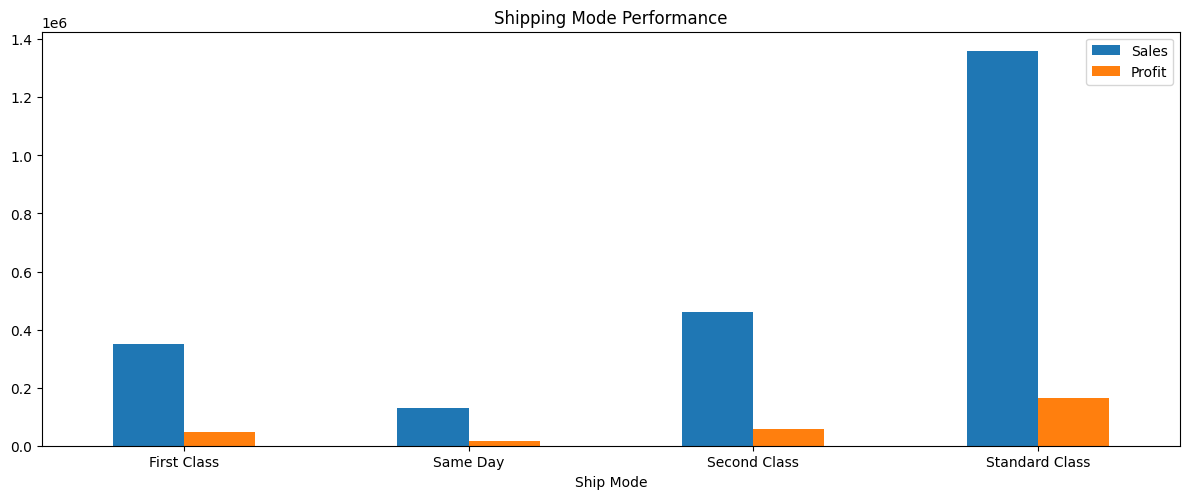

In [109]:
shipping_analysis[['Sales','Profit']].plot(kind='bar',figsize=(12,6))
plt.title('Shipping Mode Performance')
plt.tight_layout()
plt.xticks(rotation=360)
plt.show()

# State - wise Analysis

In [110]:
state_analysis = df.groupby('State').agg({'Sales':'sum','Profit':'sum'})
state_analysis

,Sales,Profit
State,,
Alabama,19510.6400,5786.8253
Arizona,35282.0010,-3427.9246
Arkansas,11678.1300,4008.6871
California,457687.6315,76381.3871
Colorado,32108.1180,-6527.8579
Connecticut,13384.3570,3511.4918
Delaware,27451.0690,9977.3748
District of Columbia,2865.0200,1059.5893
Florida,89473.7080,-3399.3017


In [111]:
# Top 10 Profitable State
top_state_profit = state_analysis.sort_values(by='Profit',ascending=False).head(10)
top_state_profit

,Sales,Profit
State,,
California,457687.6315,76381.3871
New York,310876.2710,74038.5486
Washington,138641.2700,33402.6517
Michigan,76269.6140,24463.1876
Virginia,70636.7200,18597.9504
Indiana,53555.3600,18382.9363
Georgia,49095.8400,16250.0433
Kentucky,36591.7500,11199.6966
Minnesota,29863.1500,10823.1874


In [112]:
least_state_profit = state_analysis.sort_values(by='Profit',ascending=True).head(10)
least_state_profit

,Sales,Profit
State,,
Texas,170188.0458,-25729.3563
Ohio,78258.1360,-16971.3766
Pennsylvania,116511.9140,-15559.9603
Illinois,80166.1010,-12607.8870
North Carolina,55603.1640,-7490.9122
Colorado,32108.1180,-6527.8579
Tennessee,30661.8730,-5341.6936
Arizona,35282.0010,-3427.9246
Florida,89473.7080,-3399.3017


In [117]:
city_analysis = df.groupby('City').agg({'Sales':'sum','Profit':'sum'})
city_highest_sales = city_analysis.sort_values(by='Sales',ascending=False).head(10)

In [115]:
# Top 10 Profitable City
top_city_profit = city_analysis.sort_values(by='Profit',ascending=False).head(10)
top_city_profit

,Sales,Profit
City,,
New York City,256368.161,62036.9837
Los Angeles,175851.341,30440.7579
Seattle,119540.742,29156.0967
San Francisco,112669.092,17507.3854
Detroit,42446.944,13181.7908
Lafayette,25036.200,10018.3876
Jackson,24963.858,7581.6828
Atlanta,17197.840,6993.6629
Minneapolis,16870.540,6824.5846


In [118]:
least_city_profit = city_analysis.sort_values(by='Profit',ascending=True).head(10)
least_city_profit

,Sales,Profit
City,,
Philadelphia,109077.0130,-13837.7674
Houston,64504.7604,-10153.5485
San Antonio,21843.5280,-7299.0502
Lancaster,9891.4640,-7239.0684
Chicago,48539.5410,-6654.5688
Burlington,21668.0820,-3622.8772
Dallas,20131.9322,-2846.5257
Phoenix,11000.2570,-2790.8832
Aurora,11656.4780,-2691.7386


# Order Analysis

In [119]:
# Total unique orders
total_orders = df['Order ID'].nunique()
total_orders

5009

In [120]:
# Average order Value
total_sales = df['Sales'].sum()
average_order_value = total_sales / total_orders
average_order_value

np.float64(458.6146656618087)

In [121]:
# Average items per order
items_per_order = df.groupby('Order ID').agg({'Quantity':'sum'})
average_items_per_order = items_per_order['Quantity'].mean()
average_items_per_order

np.float64(7.560990217608305)

# Correlation Analysis


In [122]:
# Coorelation Matrix
corr = df[['Sales','Quantity','Discount','Profit']].corr()
corr

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


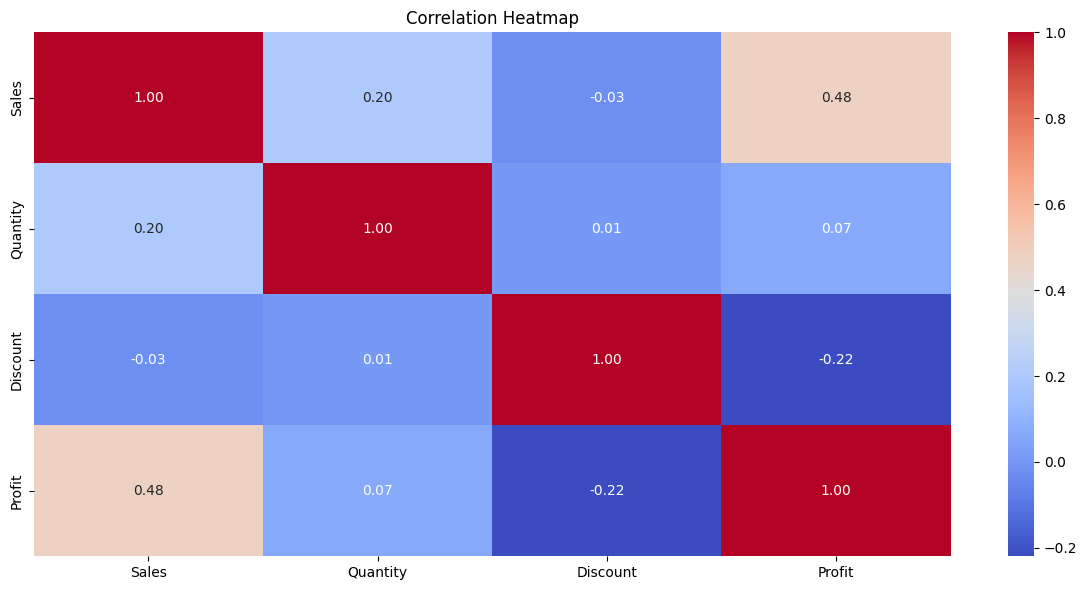

In [123]:
# Heatmap Visualization
plt.figure(figsize=(12,6))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# Descriptive Statistical Analysis


In [124]:
# Complete Statistical Summary
stats=df[['Sales','Quantity','Discount','Profit']].describe()
stats

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [126]:
# Sales and Profit Comparison
print('Average Sales',df['Sales'].mean())
print('Median Sales',df['Sales'].median())
print('Average Profit',df['Profit'].mean())
print('Median Profit',df['Profit'].median())

Average Sales 229.85800083049827
Median Sales 54.489999999999995
Average Profit 28.65689630778467
Median Profit 8.6665


# Identify outliers using IQR

In [127]:
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3 - Q1
lower= Q1 - 1.5 * IQR
higher=Q1 + 1.5 * IQR

In [129]:
outliers =df[(df['Sales'] < lower) | (df['Sales'] > higher)]
print('Sales Outlier',len(outliers))

Sales Outlier 1857


In [130]:
Q1 = df['Profit'].quantile(0.25)
Q3 = df['Profit'].quantile(0.75)
IQR = Q3 - Q1
lower= Q1 - 1.5 * IQR
higher=Q1 + 1.5 * IQR

In [132]:
profit_outliers =df[(df['Profit'] < lower) | (df['Profit'] > higher)]
print('Profit Outlier',len(profit_outliers))

Profit Outlier 2519


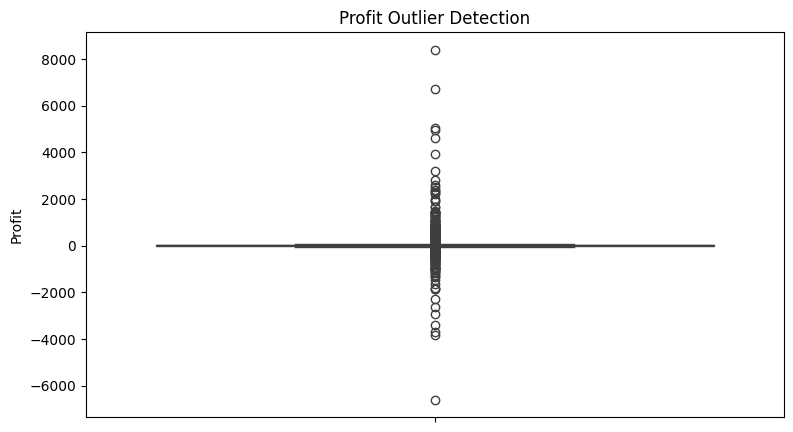

In [134]:
# profit distribution visualization
plt.figure(figsize=(9,5))
sns.boxplot(df['Profit'])
plt.title('Profit Outlier Detection')
plt.ylabel('Profit')
plt.show()

# Calculaton of KPIs
*  Total Sales
*  Total Profit
*  Total Orders
*  Average Order Value
*   Overall Profit Margin
*   Total Customers






In [135]:
# calculat KPIs
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
average_order_value = total_sales / total_orders
total_customers = df['Customer ID'].nunique()
profit_margin = (total_profit / total_sales) * 100

In [137]:
print('Total Sales',total_sales)
print('Total Profit',total_profit)
print('Total Orders',total_orders)
print('Average Order Value',average_order_value)
print('Total Customers',total_customers)
print('Profit Margin',profit_margin)

Total Sales 2297200.8603
Total Profit 286397.0217
Total Orders 5009
Average Order Value 458.6146656618087
Total Customers 793
Profit Margin 12.467217240315605


# Dashboard

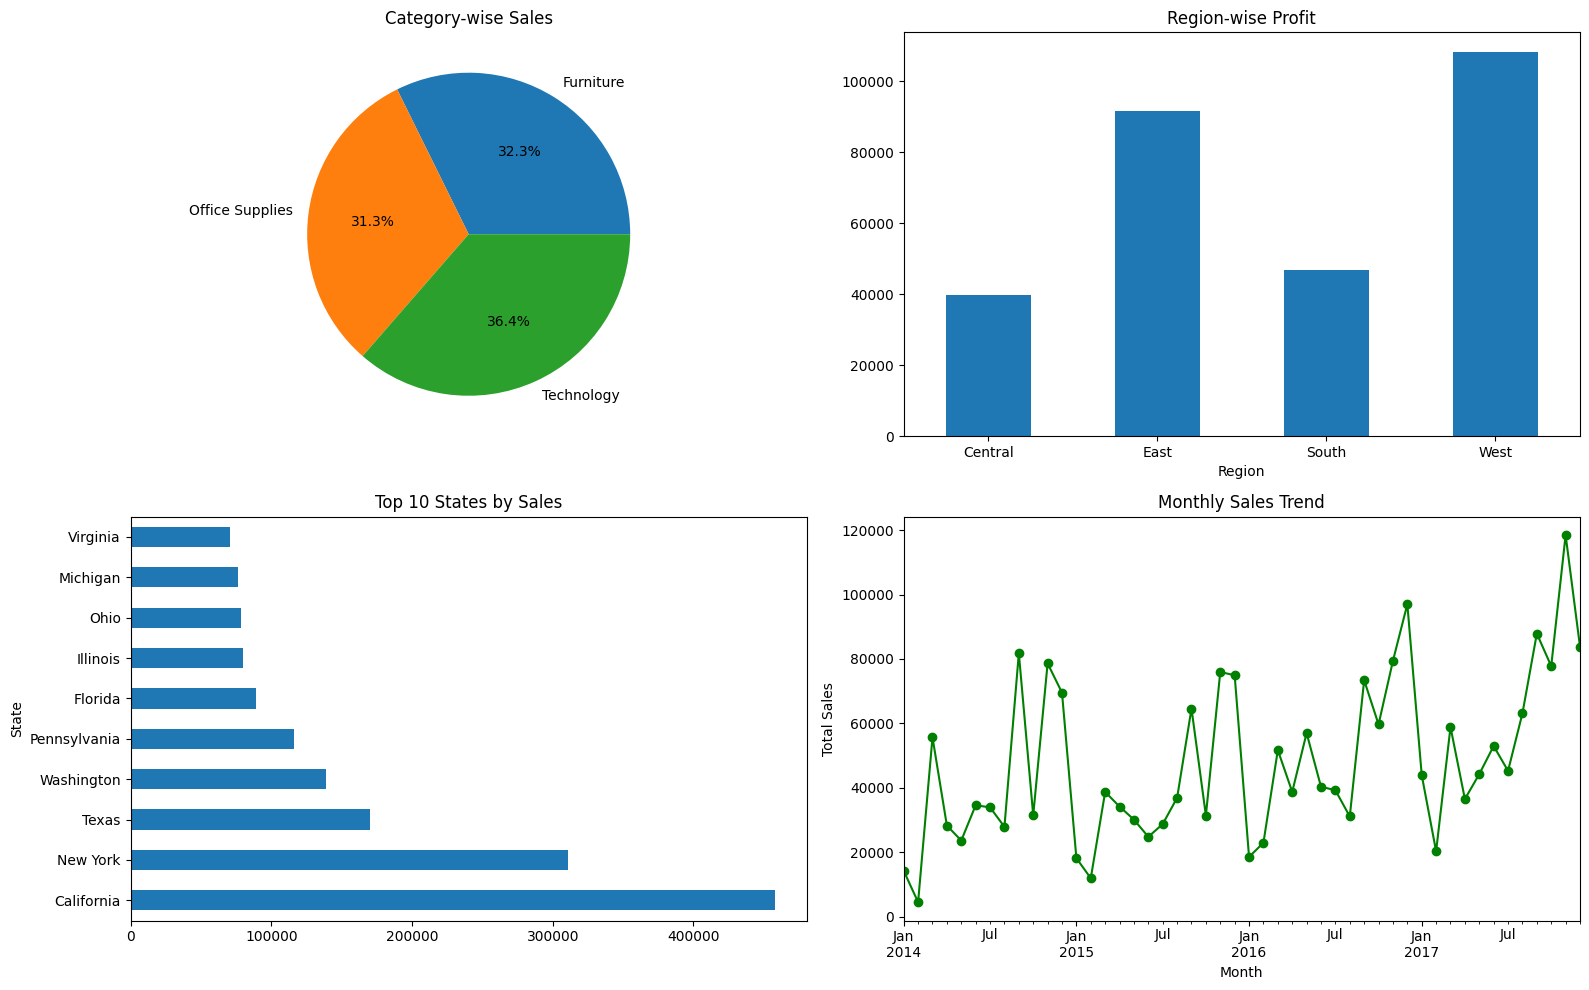

In [151]:
fig,axes= plt.subplots(2,2,figsize=(16,10))
# Category-wise Sales
df.groupby('Category')['Sales'].sum().plot(kind='pie',autopct='%1.1f%%',ax=axes[0,0],title='Category-wise Sales')
axes[0,0].set_ylabel('')

# Region-wise Profit
df.groupby('Region')['Profit'].sum().plot(kind='bar',ax=axes[0,1],title='Region-wise Profit')
axes[0,1].tick_params(axis='x',rotation=0)
# Top 10 States by Sales
df.groupby('State')['Sales'].sum().nlargest(10).plot(kind='barh',ax=axes[1,0],title='Top 10 States by Sales')
# Monthly Sales Trend
monthly_sales=(df.set_index('Order Date')['Sales'].resample('ME').sum())
axes[1,1].clear()
monthly_sales.plot(ax=axes[1,1],color='green',marker='o',legend=False,title='Monthly Sales Trend')
axes[1,1].set_xlabel('Month')
axes[1,1].set_ylabel('Total Sales')
plt.tight_layout()
plt.show()


# Business Insights


* California generated the highest total sales and profit among all states.

* Texas recorded the highest overall state-level loss.

* Standard Class shipping generated the highest sales and total profit.

* First Class shipping achieved the highest profit margin.

* Orders with a 10% discount had the highest average profit among discount level analyzed.

* Orders with a 50% discount recordd the highest average loss.

* Technology was the highest-selling product category.

* 2017 recorded the highest annual sales.

* 2016 recorded the highest year-over-year sales growth of 29.47%

* The overall business profit margin was 12.46%








# Business Recommendation


* Discount Optimization: Review high-discount orders, especially 50% discount transactions, to reduce potential losses.

* Regional Improvement: Investigate loss-making products and categories in Texas and develop strategies to improve profitabilty.

* Shipping Optimization: Maintain Standard Class as an important shipping option while evaluating the profitability of First class.

* Product Optimization: Review pricing, cost, and demand for loss-making products to improve overall profitability.

* Business Growth: Study the successful performance of California and the Technology category to identify opportunites for future growth.

# Conclusion
This project analyzed retail sales data using Python and pandas. It covered datacleaning , exploratory data analysis, customer and product analysis, sales trends, statistical analysis , and data visualization .

The analysis generated useful insights into sales performance, profitability , discount strategies, and regional performance.

The project demonstrates practical skills in Python , Pandas , data analysis , statistics, and business problem-solving.





<class 'pandas.core.series.Series'>
RangeIndex: 9994 entries, 0 to 9993
Series name: Order Date
Non-Null Count  Dtype         
--------------  -----         
9994 non-null   datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 78.2 KB
